In [1]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path(r"D:\Nhandienmau\DoAn\Original Images")
SESSIONS = ("session1", "session2")
EXTENSIONS = {".tif", ".tiff", ".png", ".jpg", ".jpeg"}
SEED = 42

In [2]:
def get_images(session):
    folder = DATA_DIR / session
    if not folder.is_dir():
        raise FileNotFoundError(f"Không tìm thấy: {folder}")
    return sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in EXTENSIONS)

images = {session: get_images(session) for session in SESSIONS}
for session, paths in images.items():
    print(f"{session}: {len(paths):,} ảnh")

session1: 6,000 ảnh
session2: 6,000 ảnh


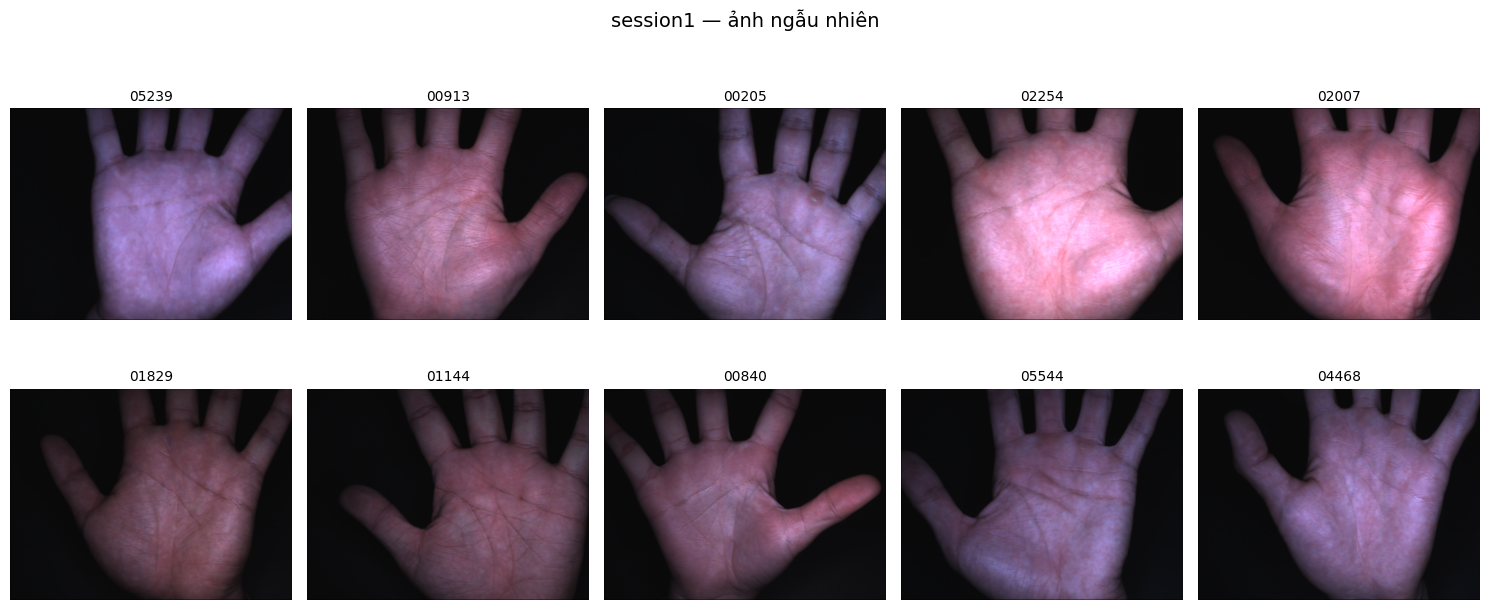

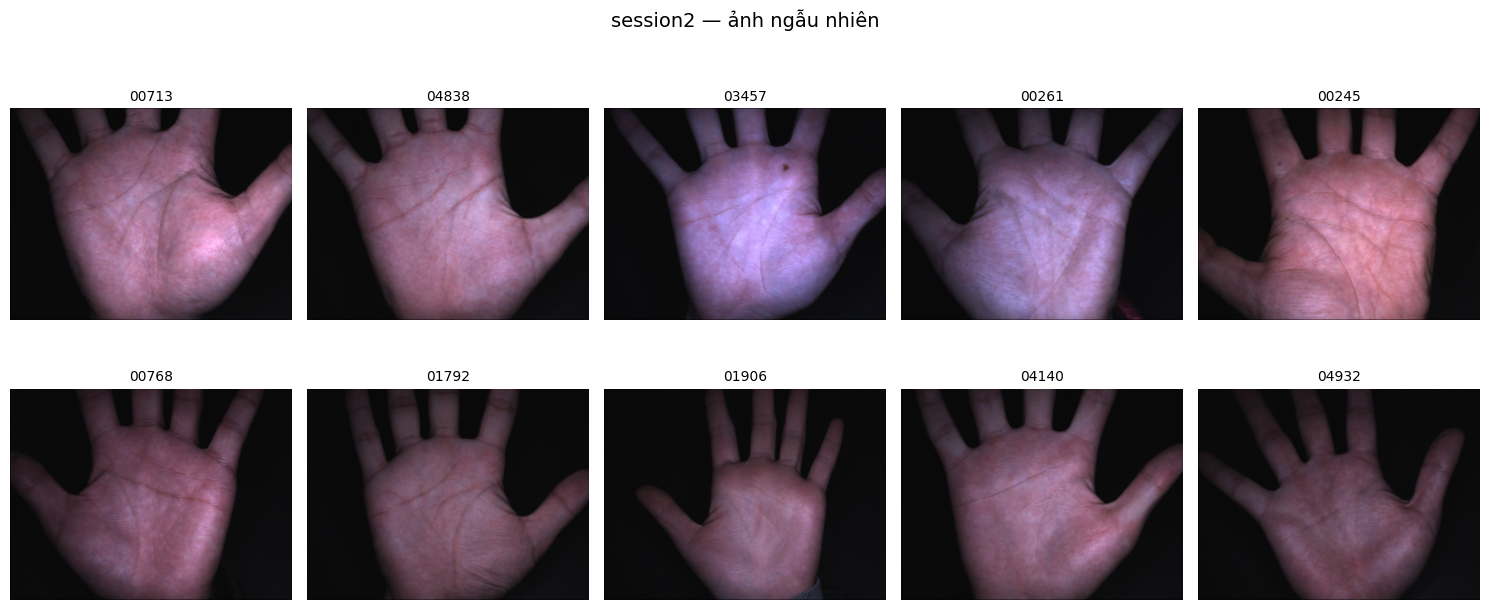

In [3]:
def show_images(paths, title, columns=5):
    if not paths:
        print("Không có ảnh để hiển thị.")
        return
    columns = min(columns, len(paths))
    rows = (len(paths) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3.4 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, path in zip(axes.flat, paths):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(path.stem, fontsize=10)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

rng = random.Random(SEED)
for session, paths in images.items():
    show_images(rng.sample(paths, min(10, len(paths))), f"{session} — ảnh ngẫu nhiên")

## So sánh cùng ảnh giữa Session 1 và Session 2
Hai file có cùng tên thuộc cùng một lòng bàn tay.

Tìm thấy 6,000 cặp ảnh trùng tên


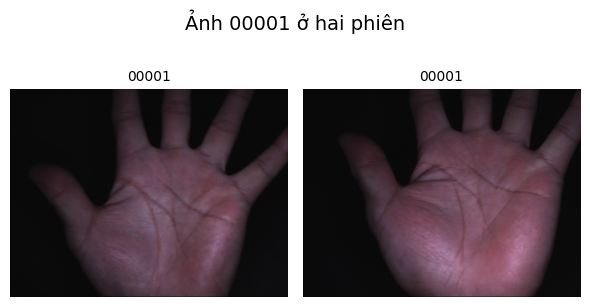

In [4]:
s2_by_name = {p.name.lower(): p for p in images["session2"]}
matched = [(p, s2_by_name[p.name.lower()]) for p in images["session1"] if p.name.lower() in s2_by_name]
print(f"Tìm thấy {len(matched):,} cặp ảnh trùng tên")
if matched:
    a, b = matched[0]
    show_images([a, b], f"Ảnh {a.stem} ở hai phiên", columns=2)

## Xem 10 ảnh của một lòng bàn tay


Palm ID 1 (session1): 10 ảnh


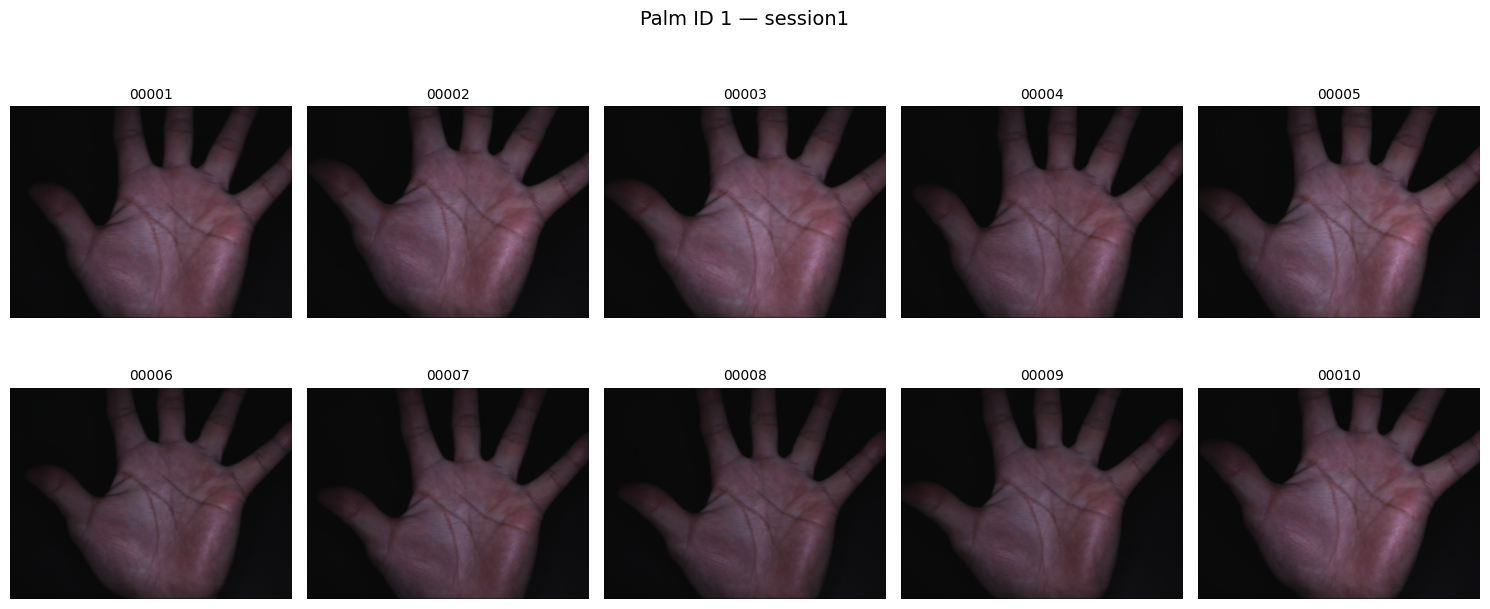

In [5]:
PALM_ID = 1
SESSION = "session1"

if not 1 <= PALM_ID <= 600:
    raise ValueError("PALM_ID phải từ 1 đến 600")

def get_palm_id(path):
    return (int(path.stem) - 1) // 10 + 1 if path.stem.isdigit() else None

selected = [p for p in images[SESSION] if get_palm_id(p) == PALM_ID]
print(f"Palm ID {PALM_ID} ({SESSION}): {len(selected)} ảnh")
show_images(selected, f"Palm ID {PALM_ID} — {SESSION}")